# Bloque 3: Data Augmentation (Aumento de Datos)

En este cuaderno se aplica e integra la etapa de **Aumento de Datos (*Data Augmentation*)** sobre el conjunto de entrenamiento (`X_train`), fundamentada en las técnicas de Procesamiento de Imágenes Digitales (PID) de los **Temas 2, 3 y 5**:
1. **Demostración práctica (Temas 2, 3 y 5):** Visualización sobre radiografías reales de las transformaciones seleccionadas (rotación leve, traslación, zoom proporcional con interpolación bilineal y relleno `nearest`, ajuste lineal de brillo/contraste $\alpha, \beta$, corrección $\gamma$ y ruido gaussiano leve) frente a las descartadas (*flip* vertical, *Swirl*, negativo, ruido sal y pimienta, Sobel/Canny/Laplaciano).
2. **Pipeline de entrenamiento al vuelo:** Implementación de las **3 variantes experimentales** definidas en la memoria sobre la arquitectura CNN base en escala de grises $(180, 180, 1)$.
3. **Evaluación comparativa:** Análisis de curvas de aprendizaje (reducción del *overfitting*), matrices de confusión y métricas clínicas priorizando la sensibilidad (*Recall*).

In [1]:
#@title 1 y 2. Configuración y Carga de Datos Preprocesados desde Drive
import os
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)
from google.colab import drive

# 1. Semilla global del proyecto (idéntica a Notebooks 1 y 4)
SEED = 230406
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# 2. Montar Google Drive y situarse en la carpeta del proyecto
drive.mount('/content/drive')

RUTA_PROYECTO = '/content/drive/MyDrive/Proyecto-neumonia'
RUTA_DATOS = os.path.join(RUTA_PROYECTO, 'Subconjunto-datos')

if not os.path.exists(RUTA_PROYECTO):
    raise FileNotFoundError(
        f"No existe la carpeta del proyecto en '{RUTA_PROYECTO}'. "
        "Ejecuta primero el Notebook 1."
    )

os.chdir(RUTA_PROYECTO)
print(f"Directorio de trabajo actual: {os.getcwd()}")

# 3. Comprobar que existen los .npy preprocesados del Notebook 1 y cargarlos
archivos_npy = ['X_train.npy', 'y_train.npy', 'X_val.npy', 'y_val.npy', 'X_test.npy', 'y_test.npy']
faltantes = [f for f in archivos_npy if not os.path.exists(os.path.join(RUTA_DATOS, f))]

if faltantes:
    raise FileNotFoundError(
        f"Faltan archivos preprocesados en '{RUTA_DATOS}': {faltantes}. "
        "Ejecuta el Notebook 1 antes de continuar."
    )

print(f"Cargando archivos .npy preprocesados desde '{RUTA_DATOS}'...")
X_train = np.load(os.path.join(RUTA_DATOS, 'X_train.npy'))
y_train = np.load(os.path.join(RUTA_DATOS, 'y_train.npy'))
X_val   = np.load(os.path.join(RUTA_DATOS, 'X_val.npy'))
y_val   = np.load(os.path.join(RUTA_DATOS, 'y_val.npy'))
X_test  = np.load(os.path.join(RUTA_DATOS, 'X_test.npy'))
y_test  = np.load(os.path.join(RUTA_DATOS, 'y_test.npy'))

print("\nResumen de dimensiones listas para Data Augmentation:")
print(f"  X_train: {X_train.shape} | y_train: {y_train.shape} | Rango: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  X_val:   {X_val.shape} | y_val:   {y_val.shape}")
print(f"  X_test:  {X_test.shape} | y_test:  {y_test.shape}")

Mounted at /content/drive
Directorio de trabajo actual: /content/drive/MyDrive/Proyecto-neumonia
Cargando archivos .npy preprocesados desde '/content/drive/MyDrive/Proyecto-neumonia/Subconjunto-datos'...

Resumen de dimensiones listas para Data Augmentation:
  X_train: (6823, 180, 180, 1) | y_train: (6823,) | Rango: [0.00, 1.00]
  X_val:   (1575, 180, 180, 1) | y_val:   (1575,)
  X_test:  (2100, 180, 180, 1) | y_test:  (2100,)


## 2. Estudio Práctico de Transformaciones PID sobre Radiografías de Tórax
Siguiendo el desarrollo teórico de la Sección 3.3 de la memoria y las prácticas de la asignatura, implementamos primero las funciones de los **Temas 2, 3 y 5** sobre una muestra del conjunto de entrenamiento (`X_train`) para verificar visualmente qué transformaciones preservan la validez anatómica y cuáles introducen artefactos diagnósticos.

In [2]:
#@title 3. Implementación de operadores de los Temas 2, 3 y 5 (Prácticas PID)

#Seleccionamos una radiografía con neumonía de X_train para las pruebas visuales
idx_muestra = np.where(y_train == 1)[0][0]
img_base = X_train[idx_muestra, :, :, 0] # Matriz 2D (180, 180) en rango [0, 1]
H, W = img_base.shape

# Referencia al tema 5: Transformaciones geométricas e interpolación bilineal
def rotacion_rigida(img, angulo_grados, fill_mode=cv.BORDER_REPLICATE):
    """Rotación rígida respecto al centro geométrico (xc, yc) con interpolación bilineal."""
    centro = (W // 2, H // 2)
    M_rot = cv.getRotationMatrix2D(centro, angulo_grados, 1.0)
    return cv.warpAffine(img, M_rot, (W, H), flags=cv.INTER_LINEAR, borderMode=fill_mode)

def traslacion_rigida(img, tx_pct, ty_pct, fill_mode=cv.BORDER_REPLICATE):
    """Traslación rígida por vector (tx, ty) usando matriz afín 2x3."""
    tx, ty = int(W * tx_pct), int(H * ty_pct)
    M_tras = np.float32([[1, 0, tx], [0, 1, ty]])
    return cv.warpAffine(img, M_tras, (W, H), flags=cv.INTER_LINEAR, borderMode=fill_mode)

def zoom_semejanza(img, factor_lambda, fill_mode=cv.BORDER_REPLICATE):
    """Re-escalado proporcional (lambda = mu) respecto al centro conservando dimensiones."""
    centro = (W // 2, H // 2)
    M_zoom = cv.getRotationMatrix2D(centro, 0, factor_lambda)
    return cv.warpAffine(img, M_zoom, (W, H), flags=cv.INTER_LINEAR, borderMode=fill_mode)

def distorsion_ripper_no_lineal(img, ax=6.0, ay=6.0, tx=45.0, ty=45.0):
    """Transformación no lineal Ripper (Tema 5) - DESCARTADA por deformar la caja torácica."""
    map_y, map_x = np.indices((H, W), dtype=np.float32)
    x_hat = map_x + ax * np.sin(2 * np.pi * map_y / tx)
    y_hat = map_y + ay * np.sin(2 * np.pi * map_x / ty)
    return cv.remap(img, x_hat, y_hat, interpolation=cv.INTER_LINEAR, borderMode=cv.BORDER_REPLICATE)

# Referencia al tema 2: Transformaciones de intensidad (Brillo, Contraste, Gamma, Negativo)
def lineal_brillo_contraste(img, alpha=1.10, beta=0.05):
    """Transformación lineal T(r) = alpha * r + beta acotada en [0, 1] (Práctica Tema 2)."""
    return np.clip(alpha * img + beta, 0.0, 1.0)

def correccion_gamma(img, gamma=0.90, c=1.0):
    """Transformación no lineal Gamma T(r) = c * r^gamma (Práctica Tema 2)."""
    return np.clip(c * np.power(np.clip(img, 1e-6, 1.0), gamma), 0.0, 1.0)

def negativo_imagen(img):
    """Transformación negativa T(r) = L - 1 - r (en rango normalizado: 1.0 - r) - DESCARTADA."""
    return 1.0 - img

# Referencia al tema 3: Modelos de ruido y filtros especiales
def ruido_gaussiano_leve(img, sigma=0.02):
    """Ruido aditivo gaussiano g(x,y) = f(x,y) + r(x,y) con sigma bajo [EN PRUEBA]."""
    ruido = np.random.normal(loc=0.0, scale=sigma, size=img.shape).astype(np.float32)
    return np.clip(img + ruido, 0.0, 1.0)

def ruido_sal_y_pimienta(img, a=0.05, b=0.05):
    """Ruido impulsivo (Práctica 2, Ej. 1) - DESCARTADO por simular falsos infiltrados."""
    aleat = np.random.randint(1, 101, size=img.shape)
    img_pim = np.where(aleat <= 100 * a, 0.0, img)
    out = np.where(aleat > 100 - 100 * b, 1.0, img_pim)
    return out.astype(np.float32)

def realce_sobel_magnitud(img):
    """Gradiente digital de 1.ª derivada con máscaras de Sobel (Tema 3) - DESCARTADO."""
    gx = cv.Sobel(img, cv.CV_32F, 1, 0, ksize=3)
    gy = cv.Sobel(img, cv.CV_32F, 0, 1, ksize=3)
    mag = cv.magnitude(gx, gy)
    return mag / (mag.max() + 1e-6)

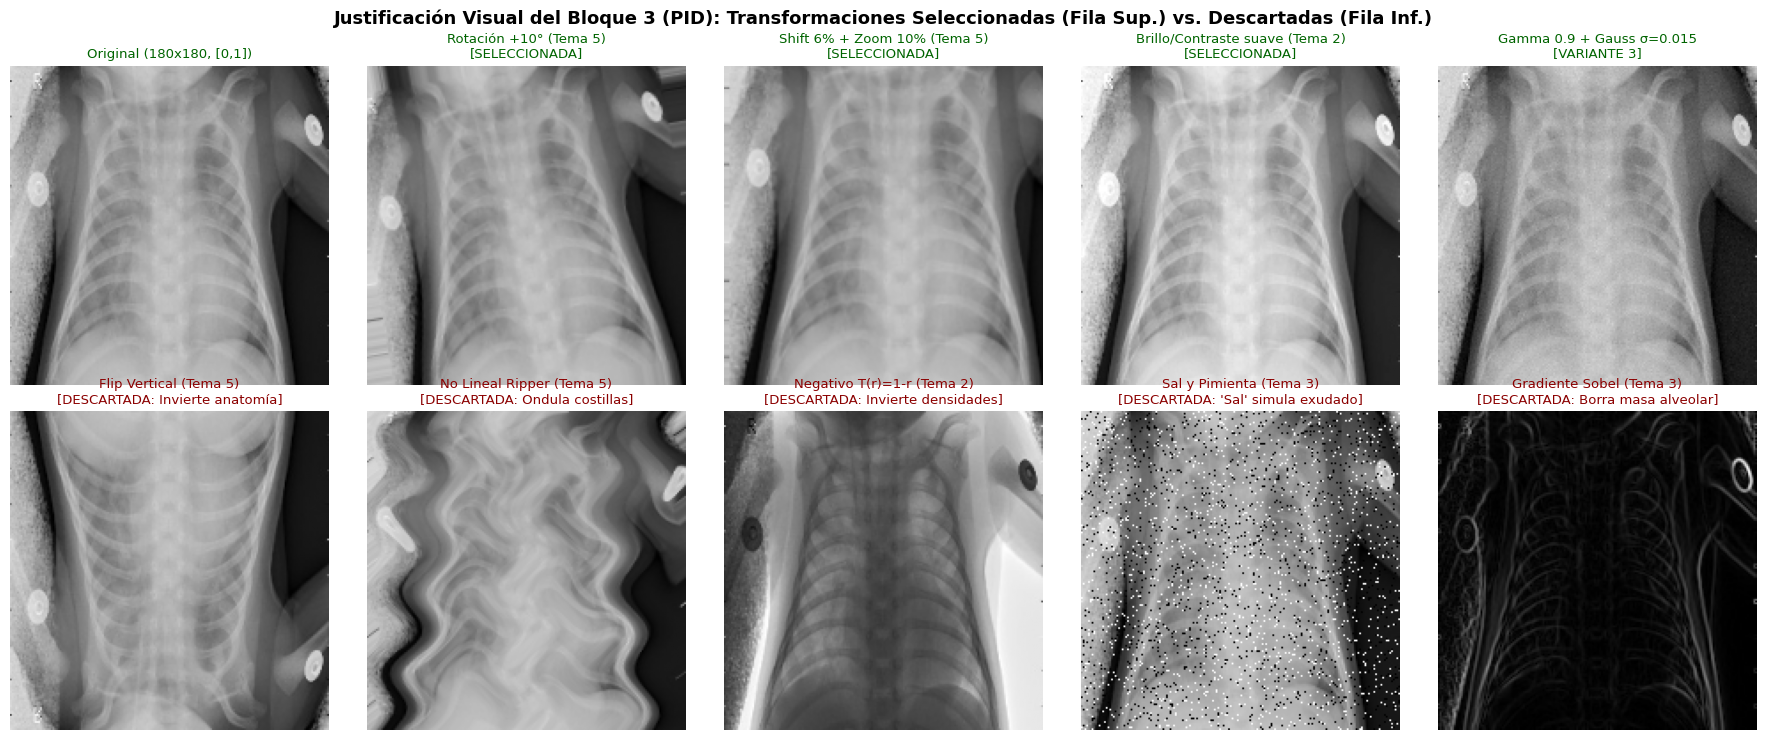

In [3]:
#@title 4. Visualización: Transformaciones SELECCIONADAS vs. DESCARTADAS (Temas 2, 3 y 5)
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
fig.suptitle("Justificación Visual del Bloque 3 (PID): Transformaciones Seleccionadas (Fila Sup.) vs. Descartadas (Fila Inf.)",
             fontsize=13, fontweight='bold')

# Fila 0: Transformaciones válidas en radiografías de tórax
ejemplos_validos = [
    (img_base, "Original (180x180, [0,1])"),
    (rotacion_rigida(img_base, 10), "Rotación +10° (Tema 5)\n[SELECCIONADA]"),
    (zoom_semejanza(traslacion_rigida(img_base, 0.06, -0.05), 1.10), "Shift 6% + Zoom 10% (Tema 5)\n[SELECCIONADA]"),
    (lineal_brillo_contraste(img_base, alpha=1.12, beta=0.04), "Brillo/Contraste suave (Tema 2)\n[SELECCIONADA]"),
    (ruido_gaussiano_leve(correccion_gamma(img_base, 0.90), sigma=0.015), "Gamma 0.9 + Gauss σ=0.015\n[VARIANTE 3]")
]

# Fila 1: Transformaciones descartadas con justificación clínica/PID
ejemplos_descartados = [
    (cv.flip(img_base, 0), "Flip Vertical (Tema 5)\n[DESCARTADA: Invierte anatomía]"),
    (distorsion_ripper_no_lineal(img_base), "No Lineal Ripper (Tema 5)\n[DESCARTADA: Ondula costillas]"),
    (negativo_imagen(img_base), "Negativo T(r)=1-r (Tema 2)\n[DESCARTADA: Invierte densidades]"),
    (ruido_sal_y_pimienta(img_base, 0.04, 0.04), "Sal y Pimienta (Tema 3)\n[DESCARTADA: 'Sal' simula exudado]"),
    (realce_sobel_magnitud(img_base), "Gradiente Sobel (Tema 3)\n[DESCARTADA: Borra masa alveolar]")
]

for col, (im, titulo) in enumerate(ejemplos_validos):
    axes[0, col].imshow(im, cmap='gray', vmin=0, vmax=1)
    axes[0, col].set_title(titulo, fontsize=9.5, color='darkgreen')
    axes[0, col].axis('off')

for col, (im, titulo) in enumerate(ejemplos_descartados):
    axes[1, col].imshow(im, cmap='gray', vmin=0, vmax=1)
    axes[1, col].set_title(titulo, fontsize=9.5, color='darkred')
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()

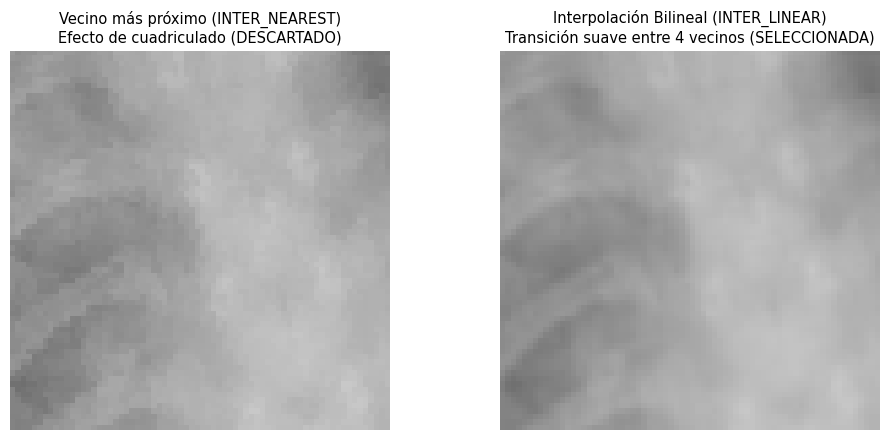

In [4]:
#@title 5. Efecto de la Interpolación en Rotación + Zoom (Vecino más próximo vs. Bilineal - Tema 5)
# Rotamos y ampliamos una región costal/pulmonar para apreciar la diferencia en detalle
centro = (W // 2, H // 2)
M_comp = cv.getRotationMatrix2D(centro, 12, 1.35)

img_nearest  = cv.warpAffine(img_base, M_comp, (W, H), flags=cv.INTER_NEAREST, borderMode=cv.BORDER_REPLICATE)
img_bilinear = cv.warpAffine(img_base, M_comp, (W, H), flags=cv.INTER_LINEAR,  borderMode=cv.BORDER_REPLICATE)

# Recorte (crop) central para observar el artefacto de cuadriculado
r0, r1, c0, c1 = 50, 120, 40, 110

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].imshow(img_nearest[r0:r1, c0:c1], cmap='gray', vmin=0, vmax=1)
ax[0].set_title("Vecino más próximo (INTER_NEAREST)\nEfecto de cuadriculado (DESCARTADO)", fontsize=10.5)
ax[0].axis('off')

ax[1].imshow(img_bilinear[r0:r1, c0:c1], cmap='gray', vmin=0, vmax=1)
ax[1].set_title("Interpolación Bilineal (INTER_LINEAR)\nTransición suave entre 4 vecinos (SELECCIONADA)", fontsize=10.5)
ax[1].axis('off')

plt.tight_layout()
plt.show()

## 3. Diseño de las 3 Variantes de *Data Augmentation* y Arquitectura Base

Tal como se establece en la Sección 3.3.5 de la memoria:
* **Aplicación exclusiva a `X_train`:** Los conjuntos `X_val` y `X_test` nunca se transforman para evaluar siempre sobre radiografías reales sin alterar.
* **Generación dinámica época a época:** En cada época se muestrean aleatoriamente los parámetros dentro de los rangos clínicos aceptados (interpolación bilineal y relleno de bordes `nearest`).
* **Comparativa de 3 Variantes progresivas sobre la misma CNN Base:**
  * **Variante 1 (Geométrico suave - Tema 5):** Rotación leve ($\pm 10^\circ$), traslación horizontal y vertical ($\pm 8\%$), zoom proporcional ($\pm 10\%$), sin *flips*.
  * **Variante 2 (Geométrico + Simetría horizontal - Tema 5):** Variante 1 añadiendo `horizontal_flip=True` (`vertical_flip=False`), evaluado según la literatura [9, 17, 18].
  * **Variante 3 (Completo PID - Temas 5 + 2 + 3):** Variante 2 incorporando perturbaciones suaves de intensidad (contraste $\alpha \in [0.90, 1.10]$, brillo $\beta \in [-0.08, +0.08]$ o corrección gamma $\gamma \in [0.90, 1.10]$) y ruido gaussiano leve ($\sigma = 0.015$).

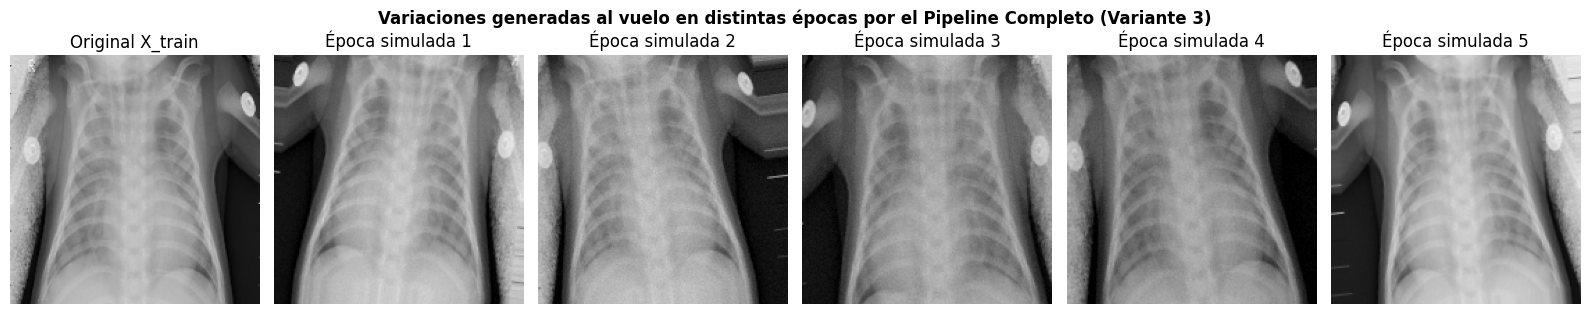

In [5]:
#@title 6. Configuración de los Generadores Dinámicos (Variantes 1, 2 y 3)
BATCH_SIZE = 32
IMG_SHAPE = (180, 180, 1)

def preprocesado_pid_temas_2_y_3(img_tensor):
    """
    Función de aumento fotométrico y espacial leve (Temas 2 y 3) para la Variante 3.
    Recibe una imagen ya transformada geométricamente en rango [0, 1] y aplica:
      1. Ajuste lineal suave de contraste (alpha) y brillo (beta) o corrección gamma (Tema 2).
      2. Ruido aditivo gaussiano de baja desviación típica sigma (Tema 3).
    """
    # 1. Transformación lineal suave T(r) = alpha * r + beta (Tema 2)
    alpha = np.random.uniform(0.90, 1.10) # Contraste +-10%
    beta  = np.random.uniform(-0.08, 0.08) # Brillo +-8%
    img_out = alpha * img_tensor + beta

    # Corrección gamma suave aleatoria (gamma en [0.90, 1.10])
    gamma = np.random.uniform(0.90, 1.10)
    img_out = np.power(np.clip(img_out, 1e-6, 1.0), gamma)

    # 2. Ruido aditivo gaussiano leve (Tema 3)
    sigma = np.random.uniform(0.0, 0.015)
    ruido = np.random.normal(0.0, sigma, size=img_out.shape).astype(np.float32)
    img_out = np.clip(img_out + ruido, 0.0, 1.0)

    return img_out.astype(np.float32)

# Variante 1: Transformaciones geométricas suaves (Tema 5)
datagen_v1 = ImageDataGenerator(
    rotation_range=10,          # Rotación rígida leve [-10°, +10°]
    width_shift_range=0.08,     # Traslación horizontal 8%
    height_shift_range=0.08,    # Traslación vertical 8%
    zoom_range=0.10,            # Re-escalado (semejanza) 10%
    horizontal_flip=False,      # Sin simetría horizontal en Variante 1
    vertical_flip=False,        # Flip vertical SIEMPRE descartado
    fill_mode='nearest'         # Relleno duplicando el borde (Tema 3 y 5)
)

# Variante 2: Geométricas suaves + Flip Horizontal (Tema 5 + Literatura [9, 18]) ---
datagen_v2 = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True,       # Se evalúa experimentalmente el flip horizontal
    vertical_flip=False,
    fill_mode='nearest'
)

# Variante 3: Pipeline completo (Temas 5 + Tema 2 + Tema 3) ---
datagen_v3 = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True,
    vertical_flip=False,
    fill_mode='nearest',
    preprocessing_function=preprocesado_pid_temas_2_y_3
)

# Visualizamos muestras generadas al vuelo por la Variante 3 sobre una misma radiografía
muestra_batch = np.expand_dims(X_train[idx_muestra], axis=0)
iterador_demo = datagen_v3.flow(muestra_batch, batch_size=1, seed=SEED)

fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
fig.suptitle("Variaciones generadas al vuelo en distintas épocas por el Pipeline Completo (Variante 3)",
             fontsize=12, fontweight='bold')
axes[0].imshow(X_train[idx_muestra, :, :, 0], cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original X_train")
axes[0].axis('off')

for i in range(1, 6):
    img_aug = next(iterador_demo)[0, :, :, 0]
    axes[i].imshow(img_aug, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title(f"Época simulada {i}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [6]:
#@title 7. Definición de la Arquitectura CNN Propia Base (Bloque 2)
# NOTA: Mantenemos exactamente las capas Conv2D(32) -> MaxPool -> Conv2D(64) -> MaxPool -> Flatten -> Dense(128) -> Dense(1)
# del Notebook 2, ajustando Input a (180, 180, 1) y eliminando Rescaling(1./255) porque X_train ya está normalizado en [0, 1].

def build_baseline_cnn(input_shape=(180, 180, 1)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Bloque Convolucional 1
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Bloque Convolucional 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Clasificador Denso
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall'),
            tf.keras.metrics.AUC(name='auc')
        ]
    )
    return model

modelo_ejemplo = build_baseline_cnn()
modelo_ejemplo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,081 (57.85 MB)

 Trainable params: 15,166,081 (57.85 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
#@title 8. Entrenamiento Experimental: Modelo Base (Sin DA) vs. Variantes 1, 2 y 3
EPOCHS = 15 # Ajustar al mismo número de épocas empleado en el Notebook 2
historiales = {}
modelos_entrenados = {}

# 0. Entrenamiento de referencia (Sin Data Augmentation) para comparación directa en las gráficas
print("\n" + "="*70)
print("ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION) COMO REFERENCIA")
print("="*70)
tf.keras.utils.set_random_seed(SEED)
model_base = build_baseline_cnn()
historiales['0_Base_Sin_DA'] = model_base.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)
modelos_entrenados['0_Base_Sin_DA'] = model_base

# Diccionario con las 3 variantes experimentales de Data Augmentation
config_variantes = {
    '1_Variante1_Geometrico': datagen_v1,
    '2_Variante2_Geom_HFlip': datagen_v2,
    '3_Variante3_PID_Completo': datagen_v3
}

for nombre_var, generador in config_variantes.items():
    print("\n" + "="*70)
    print(f"ENTRENANDO {nombre_var}")
    print("="*70)
    tf.keras.utils.set_random_seed(SEED)
    modelo = build_baseline_cnn()

    # Generador conectado EXCLUSIVAMENTE a X_train
    flujo_train = generador.flow(X_train, y_train, batch_size=BATCH_SIZE, seed=SEED, shuffle=True)

    hist = modelo.fit(
        flujo_train,
        epochs=EPOCHS,
        validation_data=(X_val, y_val), # Validación intacta sobre radiografías reales
        verbose=1
    )
    historiales[nombre_var] = hist
    modelos_entrenados[nombre_var] = modelo


ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION) COMO REFERENCIA
Epoch 1/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 26s 79ms/step - accuracy: 0.8770 - auc: 0.9485 - loss: 0.3218 - precision: 0.8816 - recall: 0.8710 - val_accuracy: 0.9435 - val_auc: 0.9844 - val_loss: 0.1551 - val_precision: 0.9475 - val_recall: 0.9391
Epoch 2/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9465 - auc: 0.9872 - loss: 0.1408 - precision: 0.9479 - recall: 0.9449 - val_accuracy: 0.9530 - val_auc: 0.9888 - val_loss: 0.1347 - val_precision: 0.9722 - val_recall: 0.9327
Epoch 3/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9629 - auc: 0.9931 - loss: 0.1028 - precision: 0.9652 - recall: 0.9604 - val_accuracy: 0.9517 - val_auc: 0.9868 - val_loss: 0.1543 - val_precision: 0.9279 - val_recall: 0.9797
Epoch 4/15
214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.9697 - auc: 0.9943 - loss: 0.0914 - precision: 0.9706 - recall: 0.9686 - val_accuracy: 0.9352 - val_auc: 0.9854 - val_loss: 0.1817 - val_pr

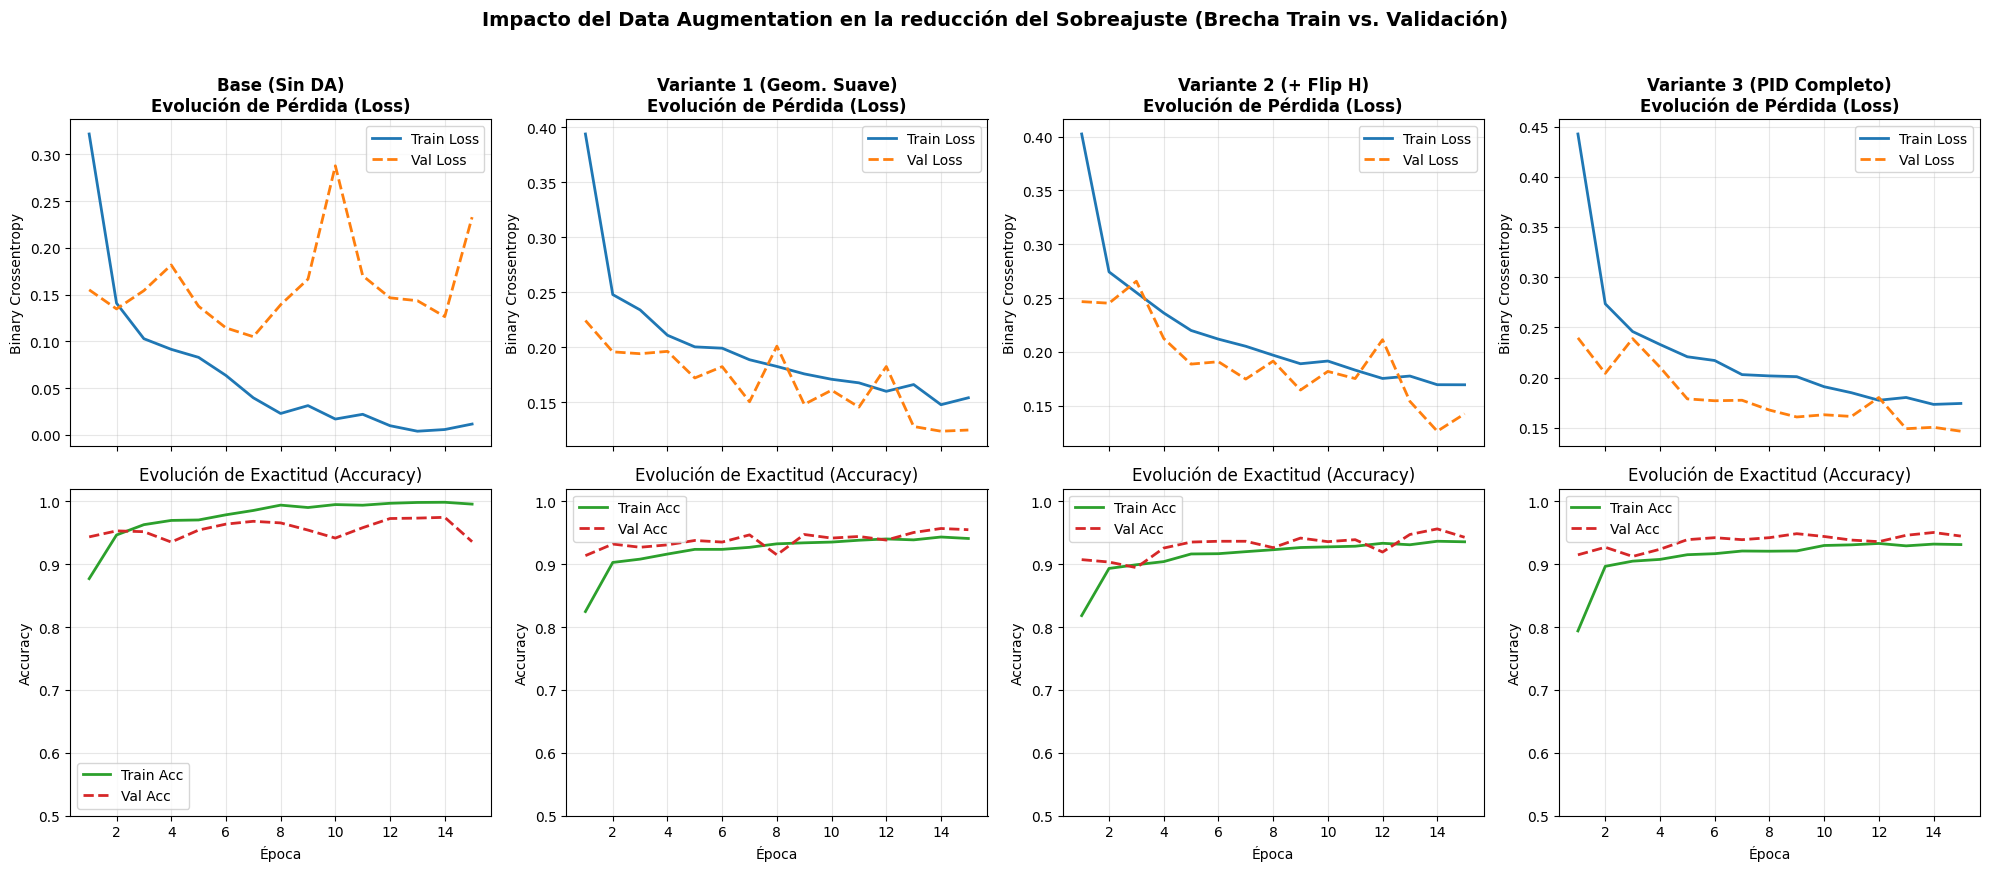

In [8]:
#@title 9. Curvas de Aprendizaje (Pérdida y Exactitud): Reducción del Sobreajuste
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), sharex=True)
nombres_bonitos = {
    '0_Base_Sin_DA': 'Base (Sin DA)',
    '1_Variante1_Geometrico': 'Variante 1 (Geom. Suave)',
    '2_Variante2_Geom_HFlip': 'Variante 2 (+ Flip H)',
    '3_Variante3_PID_Completo': 'Variante 3 (PID Completo)'
}

for col, (clave, hist) in enumerate(historiales.items()):
    h = hist.history
    epocas_rango = range(1, len(h['loss']) + 1)

    # Gráfica superior: Pérdida (Loss)
    axes[0, col].plot(epocas_rango, h['loss'], label='Train Loss', lw=2, color='tab:blue')
    axes[0, col].plot(epocas_rango, h['val_loss'], label='Val Loss', lw=2, linestyle='--', color='tab:orange')
    axes[0, col].set_title(f"{nombres_bonitos[clave]}\nEvolución de Pérdida (Loss)", fontweight='bold')
    axes[0, col].set_ylabel("Binary Crossentropy")
    axes[0, col].grid(True, alpha=0.3)
    axes[0, col].legend()

    # Gráfica inferior: Exactitud (Accuracy)
    axes[1, col].plot(epocas_rango, h['accuracy'], label='Train Acc', lw=2, color='tab:green')
    axes[1, col].plot(epocas_rango, h['val_accuracy'], label='Val Acc', lw=2, linestyle='--', color='tab:red')
    axes[1, col].set_title(f"Evolución de Exactitud (Accuracy)")
    axes[1, col].set_xlabel("Época")
    axes[1, col].set_ylabel("Accuracy")
    axes[1, col].set_ylim(0.5, 1.02)
    axes[1, col].grid(True, alpha=0.3)
    axes[1, col].legend()

plt.suptitle("Impacto del Data Augmentation en la reducción del Sobreajuste (Brecha Train vs. Validación)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

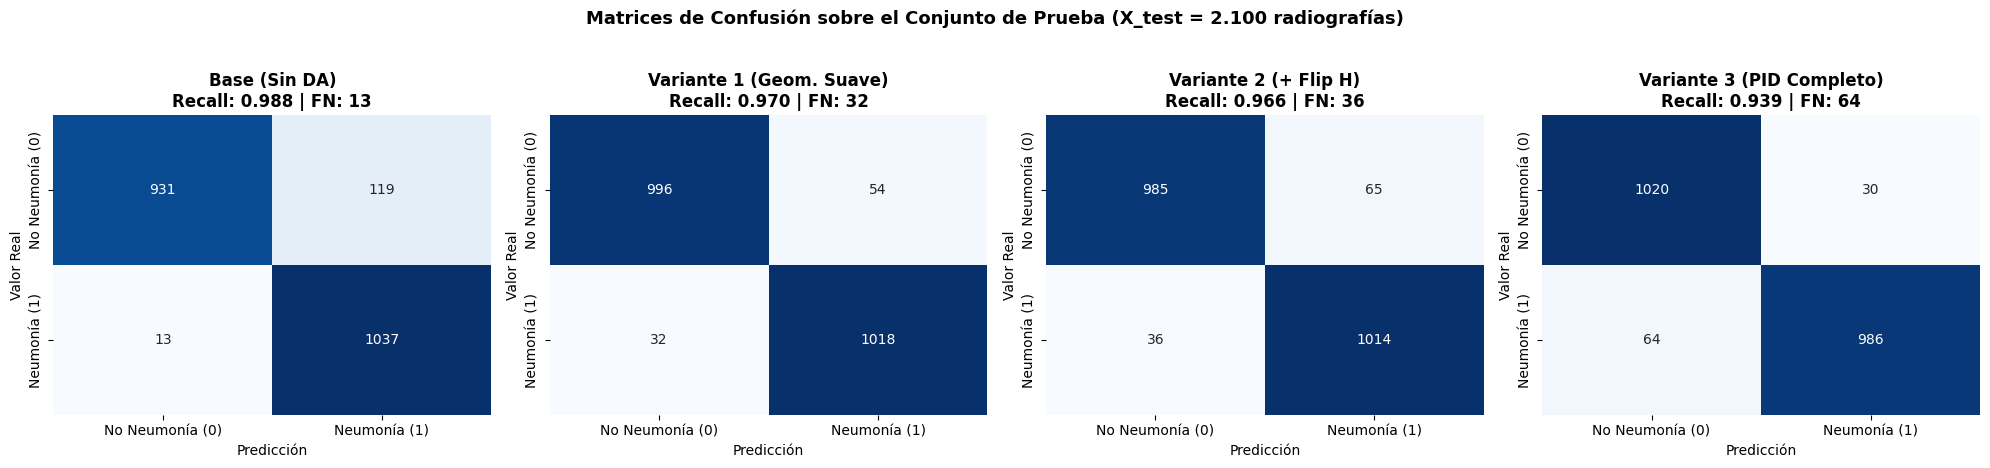

,Modelo / Variante,Accuracy,Precision,Recall (Sensibilidad),Especificidad,F1-Score,AUC-ROC,Falsos Negativos (FN),Brecha Overfitting (Train-Val Acc)
0,Base (Sin DA),0.9371,0.8971,0.9876,0.8867,0.9402,0.9909,13,0.0597
1,Variante 1 (Geom. Suave),0.9590,0.9496,0.9695,0.9486,0.9595,0.9926,32,-0.0140
2,Variante 2 (+ Flip H),0.9519,0.9398,0.9657,0.9381,0.9526,0.9899,36,-0.0072
3,Variante 3 (PID Completo),0.9552,0.9705,0.9390,0.9714,0.9545,0.9901,64,-0.0135


In [9]:
#@title 10. Evaluación bajo Protocolo Común sobre X_test (Priorizando Sensibilidad / Recall)
resultados_test = []
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for idx, (clave, modelo) in enumerate(modelos_entrenados.items()):
    # Predicciones sobre el conjunto de prueba intacto
    y_prob = modelo.predict(X_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)      # Sensibilidad clínica
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0          # Especificidad
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_prob)

    # Brecha de generalización al final del entrenamiento (Train Acc - Val Acc)
    gap_acc = historiales[clave].history['accuracy'][-1] - historiales[clave].history['val_accuracy'][-1]

    resultados_test.append({
        'Modelo / Variante': nombres_bonitos[clave],
        'Clave': clave,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall (Sensibilidad)': round(rec, 4),
        'Especificidad': round(spec, 4),
        'F1-Score': round(f1, 4),
        'AUC-ROC': round(auc, 4),
        'Falsos Negativos (FN)': int(fn),
        'Brecha Overfitting (Train-Val Acc)': round(gap_acc, 4)
    })

    # Matriz de confusión
    cm = np.array([[tn, fp], [fn, tp]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['No Neumonía (0)', 'Neumonía (1)'],
                yticklabels=['No Neumonía (0)', 'Neumonía (1)'])
    axes[idx].set_title(f"{nombres_bonitos[clave]}\nRecall: {rec:.3f} | FN: {fn}", fontweight='bold')
    axes[idx].set_xlabel('Predicción')
    axes[idx].set_ylabel('Valor Real')

plt.suptitle("Matrices de Confusión sobre el Conjunto de Prueba (X_test = 2.100 radiografías)",
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

df_resultados = pd.DataFrame(resultados_test).drop(columns=['Clave'])
display(df_resultados)

In [11]:
#@title 11. Selección de la mejor variante y guardado del dataset aumentado para el Notebook 4
# Seleccionamos entre las variantes de Data Augmentation la que maximiza Recall y F1-Score
variantes_da = [r for r in resultados_test if r['Clave'] != '0_Base_Sin_DA']
mejor_info = sorted(variantes_da, key=lambda x: (x['Recall (Sensibilidad)'], x['F1-Score']), reverse=True)[0]
mejor_clave = mejor_info['Clave']
mejor_modelo_da = modelos_entrenados[mejor_clave]

print(f"Mejor variante seleccionada: {mejor_info['Modelo / Variante']}")
print(f"  -> Recall (Sensibilidad): {mejor_info['Recall (Sensibilidad)']:.4f} (Falsos Negativos: {mejor_info['Falsos Negativos (FN)']})")
print(f"  -> F1-Score: {mejor_info['F1-Score']:.4f} | Accuracy: {mejor_info['Accuracy']:.4f} | AUC: {mejor_info['AUC-ROC']:.4f}")

# 1. Materializar el conjunto de entrenamiento aumentado con la mejor variante
# (Si ya tienes X_train_aug e y_train_aug creados en una celda anterior, borra este bloque y úsalos directamente)
mejor_datagen = config_variantes[mejor_clave]  # <-- Ajusta al nombre de tu diccionario de ImageDataGenerator

COPIAS_AUMENTADAS = 1  # 1 = duplica X_train (originales + 1 copia aumentada). Sube a 2 si quieres triplicarlo.
X_aug_lista = [X_train]
y_aug_lista = [y_train]

flujo = mejor_datagen.flow(X_train, y_train, batch_size=len(X_train), shuffle=False, seed=SEED)
for _ in range(COPIAS_AUMENTADAS):
    X_batch, y_batch = next(flujo)
    X_aug_lista.append(X_batch.astype(np.float32))
    y_aug_lista.append(y_batch.astype(y_train.dtype))

X_train_aug = np.concatenate(X_aug_lista, axis=0)
y_train_aug = np.concatenate(y_aug_lista, axis=0)

# Barajamos X_train_aug e y_train_aug de forma determinista
perm = np.random.default_rng(SEED).permutation(len(X_train_aug))
X_train_aug = X_train_aug[perm]
y_train_aug = y_train_aug[perm]

# 2. Guardar el dataset aumentado en una carpeta nueva (sin sobrescribir Subconjunto-datos)
RUTA_DATOS_AUMENTADOS = os.path.join(RUTA_PROYECTO, 'Subconjunto-datos-aumentado')
os.makedirs(RUTA_DATOS_AUMENTADOS, exist_ok=True)

# Solo se aumenta train; val y test se guardan originales para evitar data leakage
subconjuntos_aug = {
    'X_train.npy': X_train_aug,
    'y_train.npy': y_train_aug,
    'X_val.npy':   X_val,
    'y_val.npy':   y_val,
    'X_test.npy':  X_test,
    'y_test.npy':  y_test
}

for nombre, datos in subconjuntos_aug.items():
    ruta_archivo = os.path.join(RUTA_DATOS_AUMENTADOS, nombre)
    np.save(ruta_archivo, datos)

print(f"\nDataset aumentado guardado correctamente en: {RUTA_DATOS_AUMENTADOS}")
print("===== CONTENIDO DE 'Subconjunto-datos-aumentado' =====")
for item in sorted(os.listdir(RUTA_DATOS_AUMENTADOS)):
    print(f"[ARCHIVO] {item}")
print(f"Dimensiones guardadas -> X_train: {X_train_aug.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

# 3. Reporte detallado para incluir en la memoria
y_pred_best = (mejor_modelo_da.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
print("\nReporte de clasificación detallado (Mejor Variante Data Augmentation):")
print(classification_report(y_test, y_pred_best, target_names=['No Neumonía (0)', 'Neumonía (1)'], digits=4))

Mejor variante seleccionada: Variante 1 (Geom. Suave)
  -> Recall (Sensibilidad): 0.9695 (Falsos Negativos: 32)
  -> F1-Score: 0.9595 | Accuracy: 0.9590 | AUC: 0.9926

Dataset aumentado guardado correctamente en: /content/drive/MyDrive/Proyecto-neumonia/Subconjunto-datos-aumentado
===== CONTENIDO DE 'Subconjunto-datos-aumentado' =====
[ARCHIVO] X_test.npy
[ARCHIVO] X_train.npy
[ARCHIVO] X_val.npy
[ARCHIVO] y_test.npy
[ARCHIVO] y_train.npy
[ARCHIVO] y_val.npy
Dimensiones guardadas -> X_train: (13646, 180, 180, 1) | X_val: (1575, 180, 180, 1) | X_test: (2100, 180, 180, 1)

Reporte de clasificación detallado (Mejor Variante Data Augmentation):
                 precision    recall  f1-score   support

No Neumonía (0)     0.9689    0.9486    0.9586      1050
   Neumonía (1)     0.9496    0.9695    0.9595      1050

       accuracy                         0.9590      2100
      macro avg     0.9592    0.9590    0.9590      2100
   weighted avg     0.9592    0.9590    0.9590      2100

